# random forest vs xgboost

predicting house price with a random forest and with xgboost. cleaned data comes from `eda.ipynb`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, StackingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
SEED = 42

## 1. load data and hold out one listing

one random listing is taken out before any split. it is not used for training, tuning or testing, and i use it at the end to try the saved model on a house it has never seen.

In [2]:
df = pd.read_csv('../data/processed/houses_clean.csv')
df['is_member'] = df['is_member'].map({True: 1.0, False: 0.0, 'True': 1.0, 'False': 0.0})
print(df.shape)

holdout = df.sample(1, random_state=SEED)
df = df.drop(holdout.index).reset_index(drop=True)
print('rows left for training and testing:', len(df))

features = ['bedrooms', 'bathrooms', 'house_size_sqft', 'land_size_perches', 'posted_month',
            'is_verified', 'location', 'district', 'membership_level', 'is_member']
X = df[features]
y = df['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(X_train.shape, X_test.shape)

(27723, 11)
rows left for training and testing: 27722
(22177, 10) (5545, 10)


## 2. preprocessing

all of this sits in one `ColumnTransformer`, so it is fitted on the training rows only.

- numbers: fill missing with the median, `log1p` on house size and land size (both skewed), then standard scaling
- categories (location, district, membership): fill with the most common value and one hot encode. locations with fewer than 30 ads go into one rare group, and a location the model has never seen at prediction time falls into that group too
- target: price is skewed, so the model learns `log(price)` and the result is turned back into rupees

scaling does nothing for trees, but it is cheap and keeps the pipeline general.

In [3]:
log_cols = ['house_size_sqft', 'land_size_perches']
other_num = ['bedrooms', 'bathrooms', 'posted_month', 'is_verified', 'is_member']
cat_cols = ['location', 'district', 'membership_level']

preprocess = ColumnTransformer([
    ('log_num', Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
        ('scale', StandardScaler()),
    ]), log_cols),
    ('num', Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
    ]), other_num),
    ('cat', Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(min_frequency=30, handle_unknown='infrequent_if_exist', sparse_output=False)),
    ]), cat_cols),
])

def make_pipeline(regressor):
    model = TransformedTargetRegressor(regressor=regressor, func=np.log1p, inverse_func=np.expm1)
    return Pipeline([('prep', preprocess), ('model', model)])

width = preprocess.fit(X_train).get_feature_names_out().shape[0]
print('features after preprocessing:', width)

features after preprocessing: 116


## 3. default random forest and xgboost

both with default parameters, scored on the same 20% test set. rmsle and r2 are on log price, mae is in millions of rupees and the last column is the median error as a percent of the real price.

In [4]:
def evaluate(pipe):
    pred = pipe.predict(X_test)
    log_t, log_p = np.log1p(y_test), np.log1p(pred)
    return {
        'rmsle': mean_squared_error(log_t, log_p) ** 0.5,
        'r2 (log)': r2_score(log_t, log_p),
        'mae (rs m)': mean_absolute_error(y_test, pred) / 1e6,
        'median abs % error': (np.abs(pred - y_test) / y_test).median() * 100,
    }

rf_default = make_pipeline(RandomForestRegressor(random_state=SEED, n_jobs=-1)).fit(X_train, y_train)
xgb_default = make_pipeline(XGBRegressor(random_state=SEED, n_jobs=-1)).fit(X_train, y_train)

models = {'random forest (default)': rf_default, 'xgboost (default)': xgb_default}
pd.DataFrame({name: evaluate(m_) for name, m_ in models.items()}).T.round(3)

,rmsle,r2 (log),mae (rs m),median abs % error
random forest (default),0.392,0.780,7.654,15.43
xgboost (default),0.389,0.783,8.245,18.78


with the reposts removed the score is worse than before (rmsle 0.392 for the forest, it was 0.349), and this is the honest number. xgboost is a little better on rmsle (0.389) but the forest has the lower median error (15.4% against 18.8%). they are very close, so tuning is next.

## 4. choosing the parameters

defaults are made for general data, so i set the main ones myself.

**random forest**
- `n_estimators` 150, fixed. more trees only lower the variance a bit
- `max_depth` 14 to unlimited, unlimited trees memorise noise
- `min_samples_leaf` 3, 5 or 8. ads are noisy, a leaf of 1 just copies one ad
- `max_features` 0.33 to 1.0, there are many one hot columns

**xgboost**
- `learning_rate` 0.05 to 0.1, small steps overfit less
- `max_depth` 4 to 8, boosting wants shallow trees
- `subsample` and `colsample_bytree` below 1 add randomness
- `n_estimators` from early stopping, next cell

best number of rounds: 673


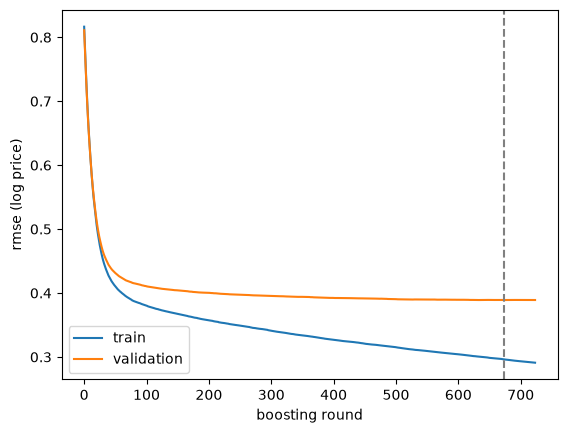

In [5]:
# how many boosting rounds are needed at lr 0.05 and depth 6?
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=SEED)
prep_tmp = clone(preprocess).fit(X_tr)

probe = XGBRegressor(n_estimators=2000, learning_rate=0.05, max_depth=6, subsample=0.8,
                     colsample_bytree=0.7, early_stopping_rounds=50, tree_method='hist', random_state=SEED, n_jobs=-1)
probe.fit(prep_tmp.transform(X_tr), np.log1p(y_tr),
          eval_set=[(prep_tmp.transform(X_tr), np.log1p(y_tr)), (prep_tmp.transform(X_val), np.log1p(y_val))],
          verbose=False)
history = probe.evals_result()
print('best number of rounds:', probe.best_iteration)

plt.plot(history['validation_0']['rmse'], label='train')
plt.plot(history['validation_1']['rmse'], label='validation')
plt.axvline(probe.best_iteration, color='grey', linestyle='--')
plt.xlabel('boosting round')
plt.ylabel('rmse (log price)')
plt.legend()
plt.show()

## 4. tuning

randomized search with 3 fold cross validation on the training set. the score is rmsle (rmse on log price), so a 10% miss counts the same for a 5 million house and a 100 million one.

In [6]:
kf = KFold(n_splits=3, shuffle=True, random_state=SEED)
score = 'neg_root_mean_squared_log_error'

rf_space = {
    'model__regressor__max_depth': [14, 18, 24, None],
    'model__regressor__min_samples_leaf': [3, 5, 8],
    'model__regressor__max_features': [0.33, 0.5, 0.7, 1.0],
}
rf_pipe = make_pipeline(RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=-1))
rf_search = RandomizedSearchCV(rf_pipe, rf_space, n_iter=6, cv=kf, scoring=score, random_state=SEED, n_jobs=1)
rf_search.fit(X_train, y_train)
print('rf best cv rmsle:', round(-rf_search.best_score_, 4))
print(rf_search.best_params_)

rf best cv rmsle: 0.4006
{'model__regressor__min_samples_leaf': 3, 'model__regressor__max_features': 0.33, 'model__regressor__max_depth': 24}


In [7]:
BEST_ROUNDS = probe.best_iteration

xgb_space = {
    'model__regressor__n_estimators': [int(BEST_ROUNDS * f) for f in (0.6, 0.8, 1.0)],
    'model__regressor__learning_rate': [0.05, 0.08, 0.1],
    'model__regressor__max_depth': [4, 6, 8],
    'model__regressor__subsample': [0.7, 0.85, 1.0],
    'model__regressor__colsample_bytree': [0.5, 0.7, 0.9],
}
xgb_pipe = make_pipeline(XGBRegressor(tree_method='hist', random_state=SEED, n_jobs=-1))
xgb_search = RandomizedSearchCV(xgb_pipe, xgb_space, n_iter=8, cv=kf, scoring=score, random_state=SEED, n_jobs=1)
xgb_search.fit(X_train, y_train)
print('xgb best cv rmsle:', round(-xgb_search.best_score_, 4))
print(xgb_search.best_params_)

xgb best cv rmsle: 0.3884
{'model__regressor__subsample': 0.7, 'model__regressor__n_estimators': 673, 'model__regressor__max_depth': 8, 'model__regressor__learning_rate': 0.05, 'model__regressor__colsample_bytree': 0.5}


In [8]:
rf_best = rf_search.best_estimator_
xgb_best = xgb_search.best_estimator_

models = {
    'random forest (default)': rf_default,
    'xgboost (default)': xgb_default,
    'random forest (tuned)': rf_best,
    'xgboost (tuned)': xgb_best,
}
pd.DataFrame({name: evaluate(m_) for name, m_ in models.items()}).T.round(3)

,rmsle,r2 (log),mae (rs m),median abs % error
random forest (default),0.392,0.780,7.654,15.430
xgboost (default),0.389,0.783,8.245,18.780
random forest (tuned),0.390,0.782,8.220,17.061
xgboost (tuned),0.376,0.798,7.841,17.294


## 5. voting and stacking

voting averages the predictions of the tuned random forest and the tuned xgboost (the regression version of soft voting). stacking trains a ridge regression on their out of fold predictions to decide how much to trust each.

In [9]:
rf_model = clone(rf_best.named_steps['model'].regressor)
xgb_model = clone(xgb_best.named_steps['model'].regressor)

voting = make_pipeline(VotingRegressor([('rf', clone(rf_model)), ('xgb', clone(xgb_model))]))
stacking = make_pipeline(StackingRegressor(
    estimators=[('rf', clone(rf_model)), ('xgb', clone(xgb_model))],
    final_estimator=RidgeCV(), cv=3))

voting.fit(X_train, y_train)
stacking.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['bedrooms','bathrooms','house_size_sqft',...,'district', 'membership_level','is_member']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log_num', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. Thi

## 6. results

everything is scored on the same 20% test set. rmsle and r2 are on log price, mae is in millions of rupees and the last column is the median error as a percent of the real price.

In [10]:
models = {
    'random forest (default)': rf_default,
    'xgboost (default)': xgb_default,
    'random forest (tuned)': rf_best,
    'xgboost (tuned)': xgb_best,
    'voting (rf + xgb)': voting,
    'stacking (rf + xgb)': stacking,
}

def evaluate(pipe):
    pred = pipe.predict(X_test)
    log_t, log_p = np.log1p(y_test), np.log1p(pred)
    return {
        'rmsle': mean_squared_error(log_t, log_p) ** 0.5,
        'r2 (log)': r2_score(log_t, log_p),
        'mae (rs m)': mean_absolute_error(y_test, pred) / 1e6,
        'median abs % error': (np.abs(pred - y_test) / y_test).median() * 100,
    }

results = pd.DataFrame({name: evaluate(m) for name, m in models.items()}).T.round(3)
results

,rmsle,r2 (log),mae (rs m),median abs % error
random forest (default),0.392,0.780,7.654,15.430
xgboost (default),0.389,0.783,8.245,18.780
random forest (tuned),0.390,0.782,8.220,17.061
xgboost (tuned),0.376,0.798,7.841,17.294
voting (rf + xgb),0.376,0.798,7.876,17.005
stacking (rf + xgb),0.374,0.800,7.772,17.016


voting gets 0.376 and stacking 0.374, only a small step from xgboost alone (0.376). the two models make similar mistakes, so averaging them adds very little. stacking is the best of the six on rmsle and r2, and the median error is about 17% for every tuned or combined model.